- **Nama**: Daffi Ramadian
- **NIM**: 245150200111040
- **BAB**: 8
- **Tanggal Praktikum**: 6 November 2026
- **Asisten Praktikum**:
    1. Jonathan Salim
    2. Rifqi Cahyono

# Bab 8 Backpropagation (1)

## Praktikum

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

### a) Fungsi *Binary Encoding* dan *Decoding*

In [4]:
def bin_enc(lbl):
  mi = min(lbl)
  length = len(bin(max(lbl) - mi + 1)[2:])
  enc = []
  for i in lbl:
    b = bin(i - mi)[2:].zfill(length)
    enc.append([int(n) for n in b])
  return enc


def bin_dec(enc, mi=0):
  lbl = []
  for e in enc:
    rounded = [int(round(x)) for x in e]
    string = "".join(str(x) for x in rounded)
    num = int(string, 2) + mi
    lbl.append(num)
  return lbl

Fungsi `bin_enc` mengubah nilai menjadi bentuk biner setelah dinormalisasi menggunakan nilai minimum. Sementara itu, `bin_dec` mengembalikan nilai biner ke bentuk desimal dan menambahkan kembali nilai minimum awal.

### b) Percobaan *Binary Encoding* dan *Decoding*

In [5]:
labels = [1, 2, 3, 4]
enc = bin_enc(labels)
dec = bin_dec(enc, min(labels))
print(enc)
print(dec)

[[0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1]]
[1, 2, 3, 4]


Pengujian menunjukkan bahwa label kelas `[1, 2, 3, 4]` berhasil diubah ke bentuk biner dan dikembalikan lagi ke array semula melalui proses decoding.

### c) Fungsi *One-hot Encoding* dan *Decoding*


In [6]:
import numpy as np


def onehot_enc(lbl, min_val=0):
  mi = min(lbl)
  enc = np.full((len(lbl), max(lbl) - mi + 1), min_val, np.int8)
  for i, x in enumerate(lbl):
    enc[i, x - mi] = 1
  return enc


def onehot_dec(enc, mi=0):
  return [np.argmax(e) + mi for e in enc]

Fungsi `onehot_enc` mengubah setiap kelas menjadi vektor berisi angka 0 dan 1 sesuai indeks kelasnya. Sementara itu, `onehot_dec` mengembalikan data ke kelas asal menggunakan `np.argmax()` untuk mencari posisi nilai 1.

### d) Percobaan *Binary Encoding* dan *Decoding*

In [7]:
labels = [1, 2, 3, 4]
enc = onehot_enc(labels)
dec = onehot_dec(enc, min(labels))
print(enc)
print(dec)

[[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


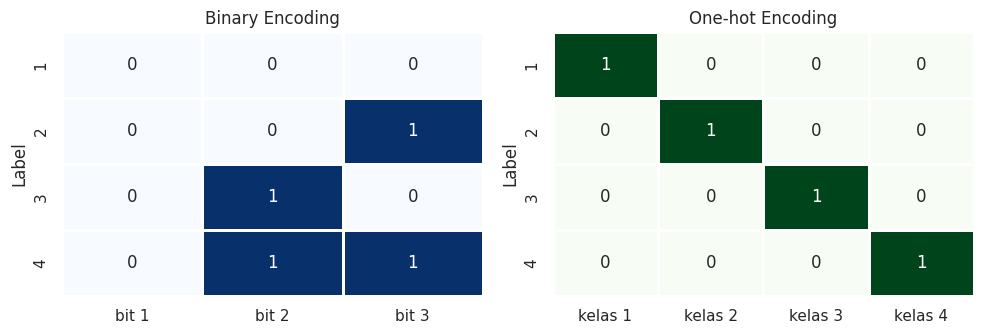

In [17]:
labels = [1, 2, 3, 4]
enc_b = np.array(bin_enc(labels))
enc_o = onehot_enc(labels)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.heatmap(enc_b, annot=True, cbar=False, cmap="Blues", linewidths=1, linecolor="white",
            xticklabels=[f"bit {i+1}" for i in range(enc_b.shape[1])],
            yticklabels=labels, ax=axes[0])
axes[0].set_title("Binary Encoding")
axes[0].set_ylabel("Label")

sns.heatmap(enc_o, annot=True, cbar=False, cmap="Greens", linewidths=1, linecolor="white",
            xticklabels=[f"kelas {l}" for l in labels],
            yticklabels=labels, ax=axes[1])
axes[1].set_title("One-hot Encoding")
axes[1].set_ylabel("Label")

plt.tight_layout()
plt.show()

Pengujian menunjukkan bahwa label `[1, 2, 3, 4]` berhasil diubah menjadi matriks identitas melalui one-hot encoding dan dikembalikan ke nilai semula melalui decoding.

### e) Fungsi Aktivasi Sigmoid dan Derivatifnya

In [8]:
def sig(X):
  return [1 / (1 + np.exp(-x)) for x in X]


def sigd(X):
  output = []
  for i, x in enumerate(X):
    s = sig([x])[0]
    output.append(s * (1 - s))
  return output

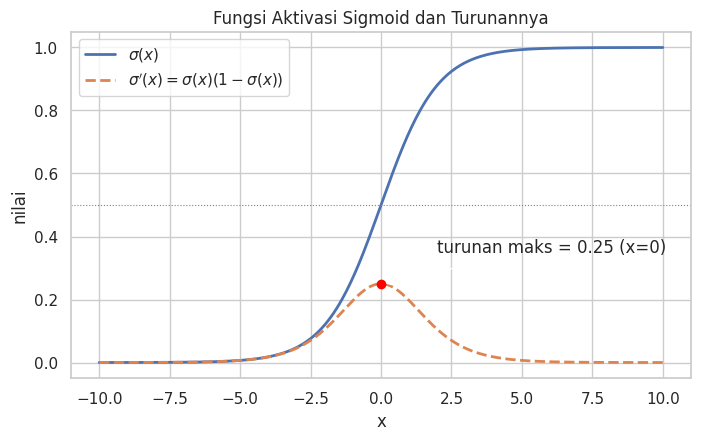

In [16]:
x = np.linspace(-10, 10, 400)
y = np.array(sig(x))
dy = np.array(sigd(x))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, y, label=r"$\sigma(x)$", linewidth=2)
ax.plot(x, dy, label=r"$\sigma'(x) = \sigma(x)(1-\sigma(x))$", linewidth=2, linestyle="--")
ax.axhline(0.5, color="gray", linewidth=0.8, linestyle=":")
ax.scatter([0], [0.25], color="red", zorder=5)
ax.annotate("turunan maks = 0.25 (x=0)", xy=(0, 0.25), xytext=(2, 0.35),
            arrowprops=dict(arrowstyle="->"))
ax.set_title("Fungsi Aktivasi Sigmoid dan Turunannya")
ax.set_xlabel("x")
ax.set_ylabel("nilai")
ax.legend()
plt.show()

Fungsi `sig` menerapkan aktivasi Sigmoid untuk menghasilkan nilai dalam rentang (0, 1). Sementara itu, `sigd` menghitung turunannya yang digunakan untuk memperbarui bobot dalam proses Backpropagation.

# Bagian Analisis

---



## Unduh Dataset Iris dan Ambil Kolom Kelas



In [9]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

filename = list(uploaded.keys())[0]
df_iris = pd.read_csv(io.BytesIO(uploaded[filename]))

kelas = df_iris.iloc[:, -1].astype(str).tolist()

Saving iris.csv to iris.csv


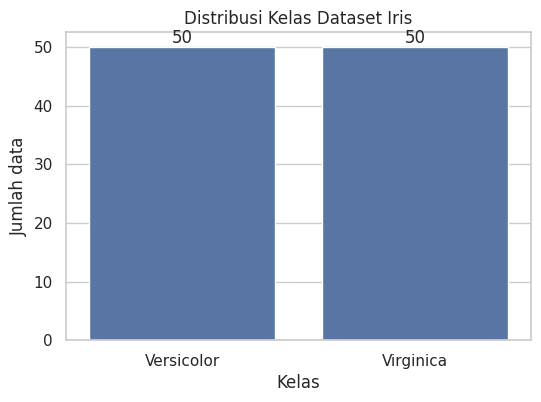

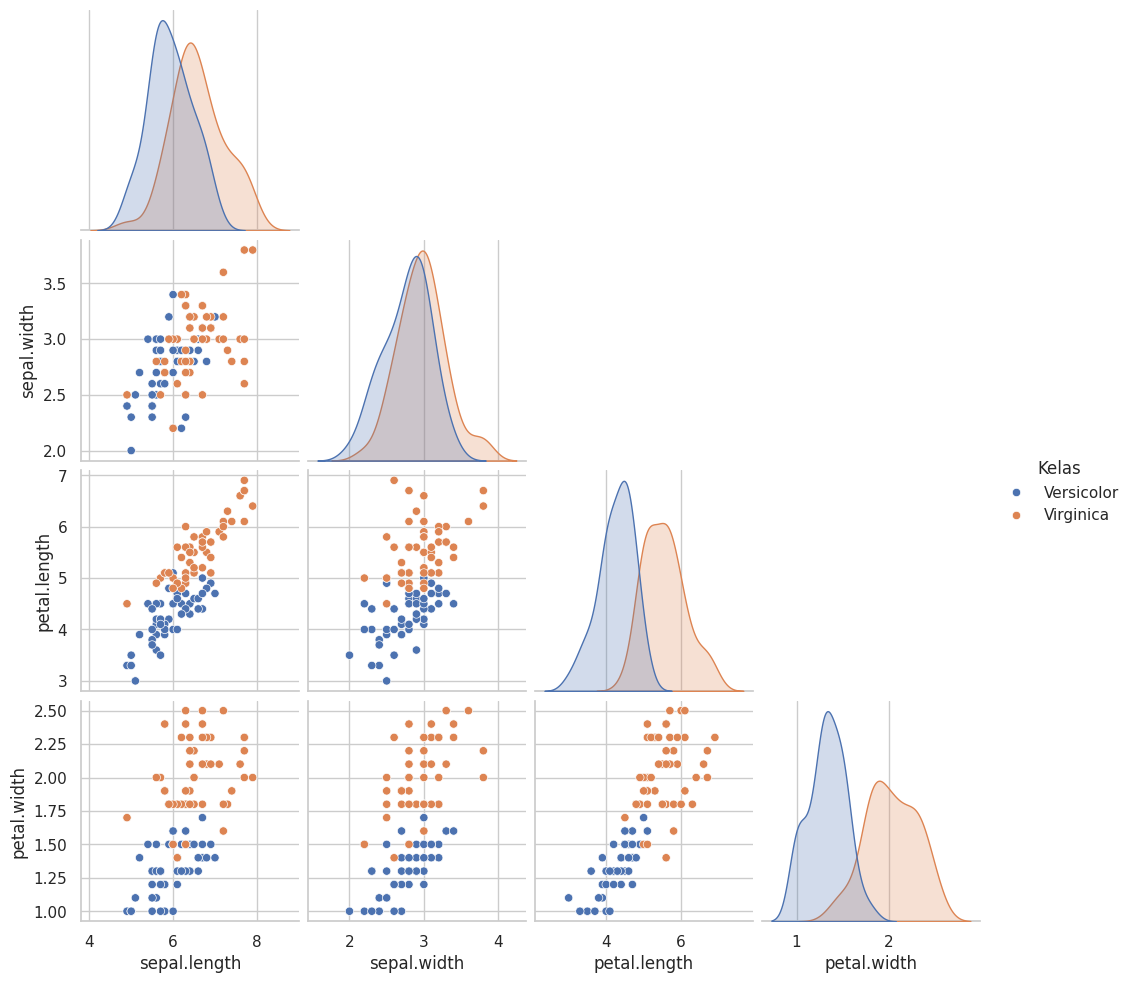

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=kelas, order=sorted(set(kelas)), ax=ax)
ax.set_title("Distribusi Kelas Dataset Iris")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah data")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

df_plot = df_iris.select_dtypes(include="number").copy()
df_plot = df_plot.loc[:, [c for c in df_plot.columns if c.lower() != "id"]]
df_plot["Kelas"] = kelas
sns.pairplot(df_plot, hue="Kelas", corner=True)
plt.show()

## Fungsi Binary Encoding & Decoding untuk String

In [10]:
def bin_enc_str(lbl_str, classes=None):
  if classes is None:
    classes = sorted(list(dict.fromkeys(lbl_str)))
  mapping = {cls_name: idx for idx, cls_name in enumerate(classes)}
  int_lbl = [mapping[s] for s in lbl_str]
  return bin_enc(int_lbl), classes


def bin_dec_str(enc, classes):
  int_dec = bin_dec(enc, mi=0)
  return [classes[i] for i in int_dec]


enc_bin_iris, classes_iris = bin_enc_str(kelas)
dec_bin_iris = bin_dec_str(enc_bin_iris, classes_iris)

print("Daftar kelas:", classes_iris)
print("Preview 5 hasil encode biner:", enc_bin_iris[:5])
print("Preview 5 hasil decode kembali:", dec_bin_iris[:5])
print("Hasil decoding cocok:", dec_bin_iris == kelas)

Daftar kelas: ['Versicolor', 'Virginica']
Preview 5 hasil encode biner: [[0, 0], [0, 0], [0, 0], [0, 0], [0, 0]]
Preview 5 hasil decode kembali: ['Versicolor', 'Versicolor', 'Versicolor', 'Versicolor', 'Versicolor']
Hasil decoding cocok: True


In [11]:
def onehot_enc_str(lbl_str, classes=None):
  if classes is None:
    classes = sorted(list(dict.fromkeys(lbl_str)))
  mapping = {cls_name: idx for idx, cls_name in enumerate(classes)}
  int_lbl = [mapping[s] for s in lbl_str]
  return onehot_enc(int_lbl), classes


def onehot_dec_str(enc, classes):
  int_dec = onehot_dec(enc, mi=0)
  return [classes[i] for i in int_dec]


enc_onehot_iris, classes_iris_oh = onehot_enc_str(kelas)
dec_onehot_iris = onehot_dec_str(enc_onehot_iris, classes_iris_oh)

print("Daftar kelas:", classes_iris_oh)
print("Preview 5 hasil encode one-hot:\n", enc_onehot_iris[:5])
print("Preview 5 hasil decode kembali:", dec_onehot_iris[:5])
print("Hasil decoding cocok:", dec_onehot_iris == kelas)

Daftar kelas: ['Versicolor', 'Virginica']
Preview 5 hasil encode one-hot:
 [[1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]]
Preview 5 hasil decode kembali: ['Versicolor', 'Versicolor', 'Versicolor', 'Versicolor', 'Versicolor']
Hasil decoding cocok: True


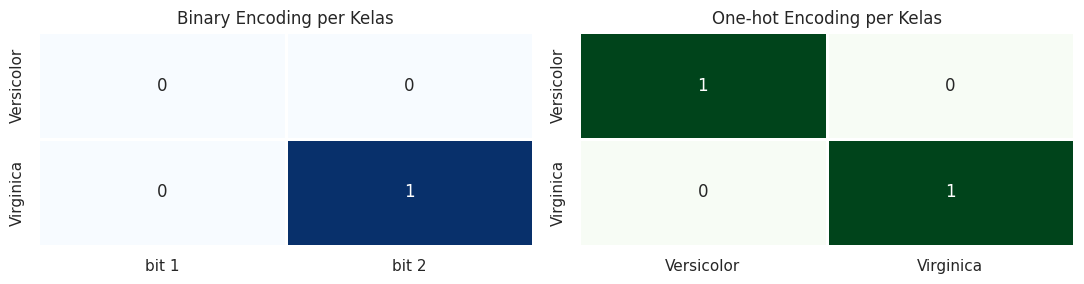

In [15]:
idx_first = [kelas.index(c) for c in classes_iris]
code_bin = np.array(enc_bin_iris)[idx_first]
code_oh = np.array(enc_onehot_iris)[idx_first]

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
sns.heatmap(code_bin, annot=True, cbar=False, cmap="Blues", linewidths=1, linecolor="white",
            xticklabels=[f"bit {i+1}" for i in range(code_bin.shape[1])],
            yticklabels=classes_iris, ax=axes[0])
axes[0].set_title("Binary Encoding per Kelas")

sns.heatmap(code_oh, annot=True, cbar=False, cmap="Greens", linewidths=1, linecolor="white",
            xticklabels=classes_iris, yticklabels=classes_iris, ax=axes[1])
axes[1].set_title("One-hot Encoding per Kelas")

plt.tight_layout()
plt.show()

**Penjelasan Bagian Analisis:**

Fungsi `bin_enc_str` dan `onehot_enc_str` digunakan untuk mengubah label kelas yang awalnya berupa string menjadi angka melalui mapping dictionary. Setiap kelas unik akan diberikan nilai integer yang berbeda, kemudian nilai tersebut diproses menggunakan binary encoding atau one-hot encoding. Untuk mengembalikan data ke bentuk semula, fungsi decoding mengubah hasil encoding menjadi nilai integer terlebih dahulu, lalu mencocokkannya kembali dengan label string berdasarkan dictionary yang telah disimpan. Hasil pengecekan `dec_bin_iris == kelas` menghasilkan `True`, yang menunjukkan bahwa seluruh proses encoding dan decoding berjalan dengan benar. Artinya, label kelas Iris berhasil dikembalikan ke bentuk string semula tanpa kehilangan informasi maupun mengubah urutan data.